# Análise Exploratória — Wine Quality

Este notebook explora o dataset **já limpo** (`data/processed/winequality_clean.csv`,
gerado por `data/processing.py`). Os problemas do dataset bruto e as correções
aplicadas estão documentados em `raw_data_investigation.ipynb` e no README.

O objetivo é entender as variáveis e a relação delas com a `quality` (target)
para embasar as decisões de pré-processamento e modelagem das partes de
regressão e classificação.

## 1. Setup

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/winequality_clean.csv")

## 2. Visão geral dos dados

Dimensões, tipos das colunas, estatísticas descritivas e valores vazios que
restaram após a limpeza.

In [6]:
print(f"{df.shape[0]} linhas x {df.shape[1]} colunas")
print(df["type"].value_counts())
print()

df.info()

5317 linhas x 13 colunas
type
white    3958
red      1359
Name: count, dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 5317 entries, 0 to 5316
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5315 non-null   float64
 1   volatile acidity      5317 non-null   float64
 2   citric acid           5315 non-null   float64
 3   residual sugar        5316 non-null   float64
 4   chlorides             5316 non-null   float64
 5   free sulfur dioxide   5315 non-null   float64
 6   total sulfur dioxide  5317 non-null   float64
 7   density               5315 non-null   float64
 8   pH                    5315 non-null   float64
 9   sulphates             5222 non-null   float64
 10  alcohol               5317 non-null   float64
 11  type                  5317 non-null   str    
 12  quality               5317 non-null   int64  
dtypes: float64(11), int64(1), str(1)
memory usage: 54

In [7]:
# .T transpõe a tabela: uma linha por variável fica mais fácil de ler
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5315.0,7.216,1.320,3.800,6.400,7.000,7.700,15.900
volatile acidity,5317.0,0.344,0.168,0.080,0.230,0.300,0.410,1.580
citric acid,5315.0,0.318,0.147,0.000,0.240,0.310,0.400,1.660
residual sugar,5316.0,5.049,4.501,0.600,1.800,2.700,7.500,65.800
chlorides,5316.0,0.057,0.037,0.009,0.038,0.047,0.066,0.611
free sulfur dioxide,5315.0,30.031,17.808,1.000,16.000,28.000,41.000,289.000
total sulfur dioxide,5317.0,114.085,56.781,6.000,74.000,116.000,153.000,440.000
density,5315.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,5315.0,3.225,0.160,2.720,3.110,3.210,3.330,4.010
sulphates,5222.0,0.534,0.149,0.220,0.430,0.510,0.600,2.000


In [8]:
# Mostra só as colunas que ainda têm vazios; serão imputados após o split treino/teste
vazios = df.isna().sum()
vazios[vazios > 0].sort_values(ascending=False)

sulphates              95
fixed acidity           2
free sulfur dioxide     2
citric acid             2
density                 2
pH                      2
chlorides               1
residual sugar          1
dtype: int64

### Observações

**1. O dataset limpo tem 5.317 vinhos e 13 colunas, com cerca de 3 brancos para cada tinto.**
São 3.958 brancos e 1.359 tintos. As 11 variáveis físico-químicas são numéricas
(`float64`), a `quality` é inteira e o `type` é texto: a limpeza deixou cada coluna
com o tipo certo.
→ O desbalanceamento entre os tipos precisa ser levado em conta nos gráficos
(seção 4) e reforça incluir o `type` como variável.

**2. Em várias variáveis, a média é bem maior que a mediana.**
Em `residual sugar`, a média é 5,05 e a mediana, 2,7; em `chlorides`, 0,057 contra 0,047.
Isso indica cauda longa à direita: poucos valores altos puxam a média para cima.
→ Será confirmado nos histogramas (seção 4).

**3. As variáveis estão em escalas muito diferentes.**
O desvio padrão de `density` é 0,003, enquanto o de `total sulfur dioxide` é 56,8.
→ É necessário padronizar antes de modelos sensíveis à escala.

**4. Restam poucos valores vazios.**
`sulphates` tem 95 (1,8% das linhas); as demais colunas têm no máximo 2.
→ Como são poucos, serão imputados (e não removidos), depois do split treino/teste.

## 3. Variável alvo (`quality`)

Distribuição das notas, separada por tipo de vinho.

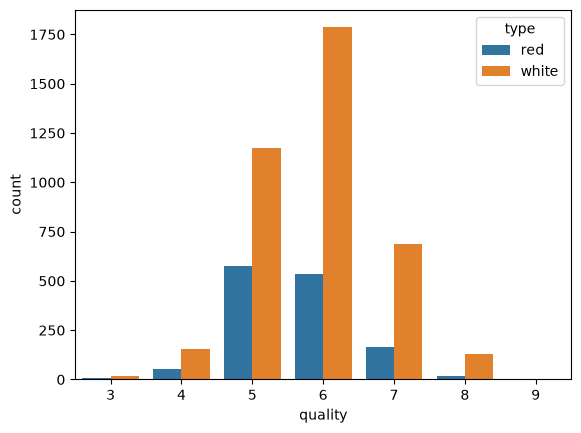

quality
3    0.005642
4    0.038744
5    0.329509
6    0.436336
7    0.160993
8    0.027835
9    0.000940
Name: proportion, dtype: float64


In [4]:
sns.countplot(data=df, x="quality", hue="type")
plt.show()

print(df["quality"].value_counts(normalize=True).sort_index())

### Observações

**1. As notas se concentram em 5 e 6.**
A nota 6 representa cerca de 43% dos vinhos e a nota 5 cerca de 33%:
juntas, somam aproximadamente 3 em cada 4 amostras. A nota 7 tem
cerca de 16%, e as notas 3, 4, 8 e 9 somadas não chegam a 8%.

**2. Apenas as notas de 3 a 9 aparecem.**
Embora a escala vá de 0 a 10, nenhum vinho recebeu notas extremas
(0, 1, 2 ou 10). A nota 9 tem apenas 5 amostras, todas de vinho branco.

**3. Tintos e brancos têm notas um pouco diferentes.**
No vinho tinto, a nota mais comum é 5; no branco, é 6.

**O que isso significa para os modelos:**
- **Regressão:** com tantas amostras perto de 5 e 6, o modelo tende
  a prever valores nessa região e deve errar mais nos vinhos muito
  bons ou muito ruins.
- **Classificação:** prever a nota exata seria inviável para as notas
  raras (5 amostras de nota 9 não bastam para o modelo aprender).
  Isso justifica agrupar as notas em faixas, como pede o enunciado,
  e avaliar técnicas de balanceamento.
- **Divisão treino/teste:** a separação deve ser estratificada pela
  `quality`, para que as notas raras apareçam nos dois conjuntos.

## 4. Distribuição das variáveis (histogramas)

Como há cerca de 3× mais vinhos brancos (3.958) que tintos (1.359), cada
tipo foi normalizado separadamente (`stat="density", common_norm=False`):
assim os histogramas comparam o **formato** das distribuições de tintos e
brancos, e não a quantidade de vinhos de cada tipo. O tamanho de cada grupo
aparece na legenda.

In [ ]:
# Apenas as 11 features; a quality já foi analisada na seção 3
colunas_numericas = df.select_dtypes("number").columns.drop("quality")

# Rótulo da legenda com o tamanho de cada grupo, ex.: "white (n=3958)"
n = df["type"].value_counts()
df_hist = df.assign(tipo=df["type"].map(lambda t: f"{t} (n={n[t]})"))

# Uma grade de 4 linhas x 3 colunas, um gráfico para cada variável
# (11 variáveis: a última posição da grade fica vazia)
fig, eixos = plt.subplots(4, 3, figsize=(16, 14))

for eixo, coluna in zip(eixos.flatten(), colunas_numericas):
    sns.histplot(data=df_hist, x=coluna, hue="tipo", bins=40, ax=eixo,
                 stat="density", common_norm=False)
    eixo.set_title(coluna)
    # "Density" do seaborn se confundiria com a variável density
    eixo.set_ylabel("Densidade (normalizada por tipo)")

eixos.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()

### Observações dos histogramas

**1. Vinhos tintos e brancos têm perfis químicos diferentes.**
O `total sulfur dioxide` mostra a maior separação: os tintos ficam
quase todos abaixo de 75, e os brancos se concentram entre 100 e 200.
Os tintos também têm mais `volatile acidity`, `chlorides` e
`sulphates`; os brancos têm mais `residual sugar`.
→ O `type` deve entrar como variável no modelo.

**2. Várias variáveis são assimétricas, com cauda longa à direita.**
`residual sugar`, `chlorides`, `free sulfur dioxide` e `sulphates`
concentram a maioria dos valores à esquerda, com poucos valores muito altos.
→ Modelos lineares podem ser afetados; uma transformação logarítmica
pode ser testada.

**3. As variáveis estão em escalas muito diferentes.**
`density` varia entre 0,99 e 1,04, enquanto `total sulfur dioxide`
vai de 6 a 440.
→ É necessário padronizar os dados antes de modelos sensíveis a
escala, como regressão linear regularizada, KNN e SVM.

**4. Existem valores extremos, mas eles são reais.**
Os eixos se estendem bem além da maioria dos dados (`residual sugar`
até 65,8, `free sulfur dioxide` até 289), por causa de poucas amostras.
Esses valores estão dentro das faixas do artigo original.
→ Serão analisados com boxplots; a princípio, devem ser mantidos.

## 5. Outliers (boxplots)

Os histogramas mostraram caudas longas em várias variáveis. Aqui os boxplots
mostram quantos valores ficam fora do intervalo interquartil (IQR) e se é
o caso de mantê-los ou removê-los.

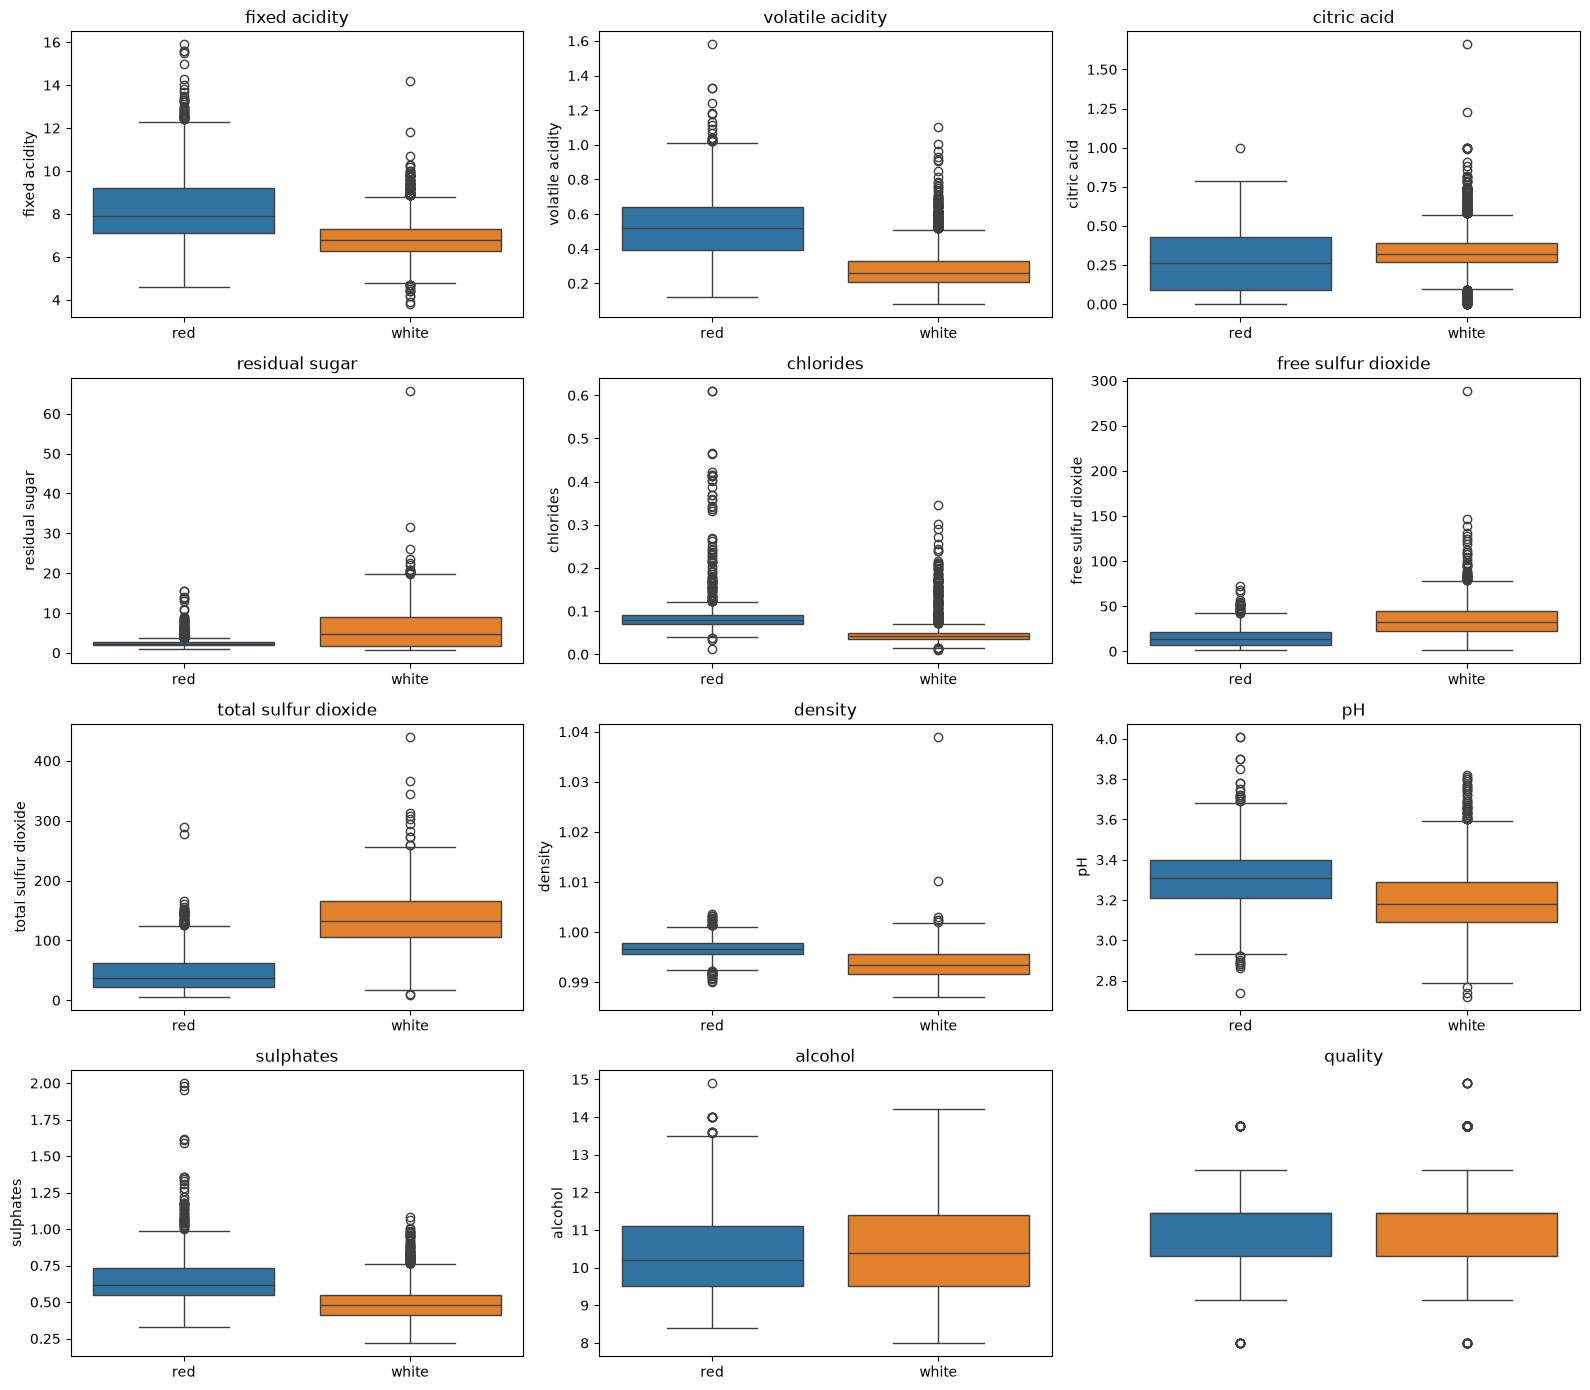

In [9]:
# Mesma grade da seção 4: um boxplot por variável, tintos e brancos lado a lado
fig, eixos = plt.subplots(4, 3, figsize=(16, 14))

for eixo, coluna in zip(eixos.flatten(), colunas_numericas):
    # hue="type" mantém as mesmas cores dos histogramas
    sns.boxplot(data=df, x="type", y=coluna, hue="type", legend=False, ax=eixo)
    eixo.set_title(coluna)
    eixo.set_xlabel("")

eixos.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()

In [10]:
def percentual_outliers(serie):
    """% de valores fora do intervalo [Q1 - 1,5*IQR, Q3 + 1,5*IQR] (critério do boxplot)."""
    serie = serie.dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    fora = (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)
    return fora.mean() * 100


# Calculado separadamente por tipo, porque tintos e brancos têm distribuições diferentes
outliers = df.groupby("type")[colunas_numericas].agg(percentual_outliers).T.round(1)
outliers.sort_values("white", ascending=False)

type,red,white
citric acid,0.1,5.6
chlorides,6.4,4.7
quality,2.0,3.9
volatile acidity,1.4,3.4
fixed acidity,3.0,2.7
sulphates,4.0,2.5
pH,2.1,1.2
free sulfur dioxide,1.9,1.1
residual sugar,9.3,0.4
total sulfur dioxide,3.3,0.4


### Observações

**1. Todas as variáveis têm outliers pelo critério do IQR, mas em proporção pequena.**
O maior caso é `residual sugar` nos tintos (9,3%), seguido de `chlorides` nos tintos (6,4%)
e `citric acid` nos brancos (5,6%). Nas demais, a proporção fica abaixo de 5%.

**2. O caso de `residual sugar` nos tintos vem da distribuição estreita.**
Quase todos os tintos são secos, com o açúcar muito concentrado em valores baixos.
A caixa do boxplot fica estreita, e qualquer tinto um pouco mais doce já aparece como outlier.

**3. Outlier pelo IQR não é erro.**
Os valores impossíveis já foram tratados na limpeza (`processing.py`). O que sobrou está
dentro das faixas do artigo original: são vinhos reais, só que incomuns.
→ **Os outliers serão mantidos.** Removê-los tiraria justamente os vinhos diferentes, que
podem ser os de nota rara. Para reduzir o efeito deles, podem ser testados a transformação
log, o `RobustScaler` (usa mediana e IQR em vez de média e desvio padrão) ou modelos
baseados em árvore, que são pouco sensíveis a outliers.

## 6. Relação das variáveis com a qualidade

Como a `quality` só assume valores inteiros, um scatter plot de feature × quality
formaria faixas horizontais. Por isso são usados boxplots de cada variável por nota.

Os vinhos são separados por `type` porque a proporção de brancos cresce nas notas
altas (67% na nota 5, 89% na nota 8, 100% na nota 9). Sem a separação, uma
tendência poderia refletir apenas a mistura de tipos, e não a qualidade.

As notas 3 (30 vinhos) e 9 (5 vinhos, todos brancos) têm poucas amostras, assim
como a nota 8 entre os tintos: essas caixas são menos confiáveis e devem ser
interpretadas com cautela.

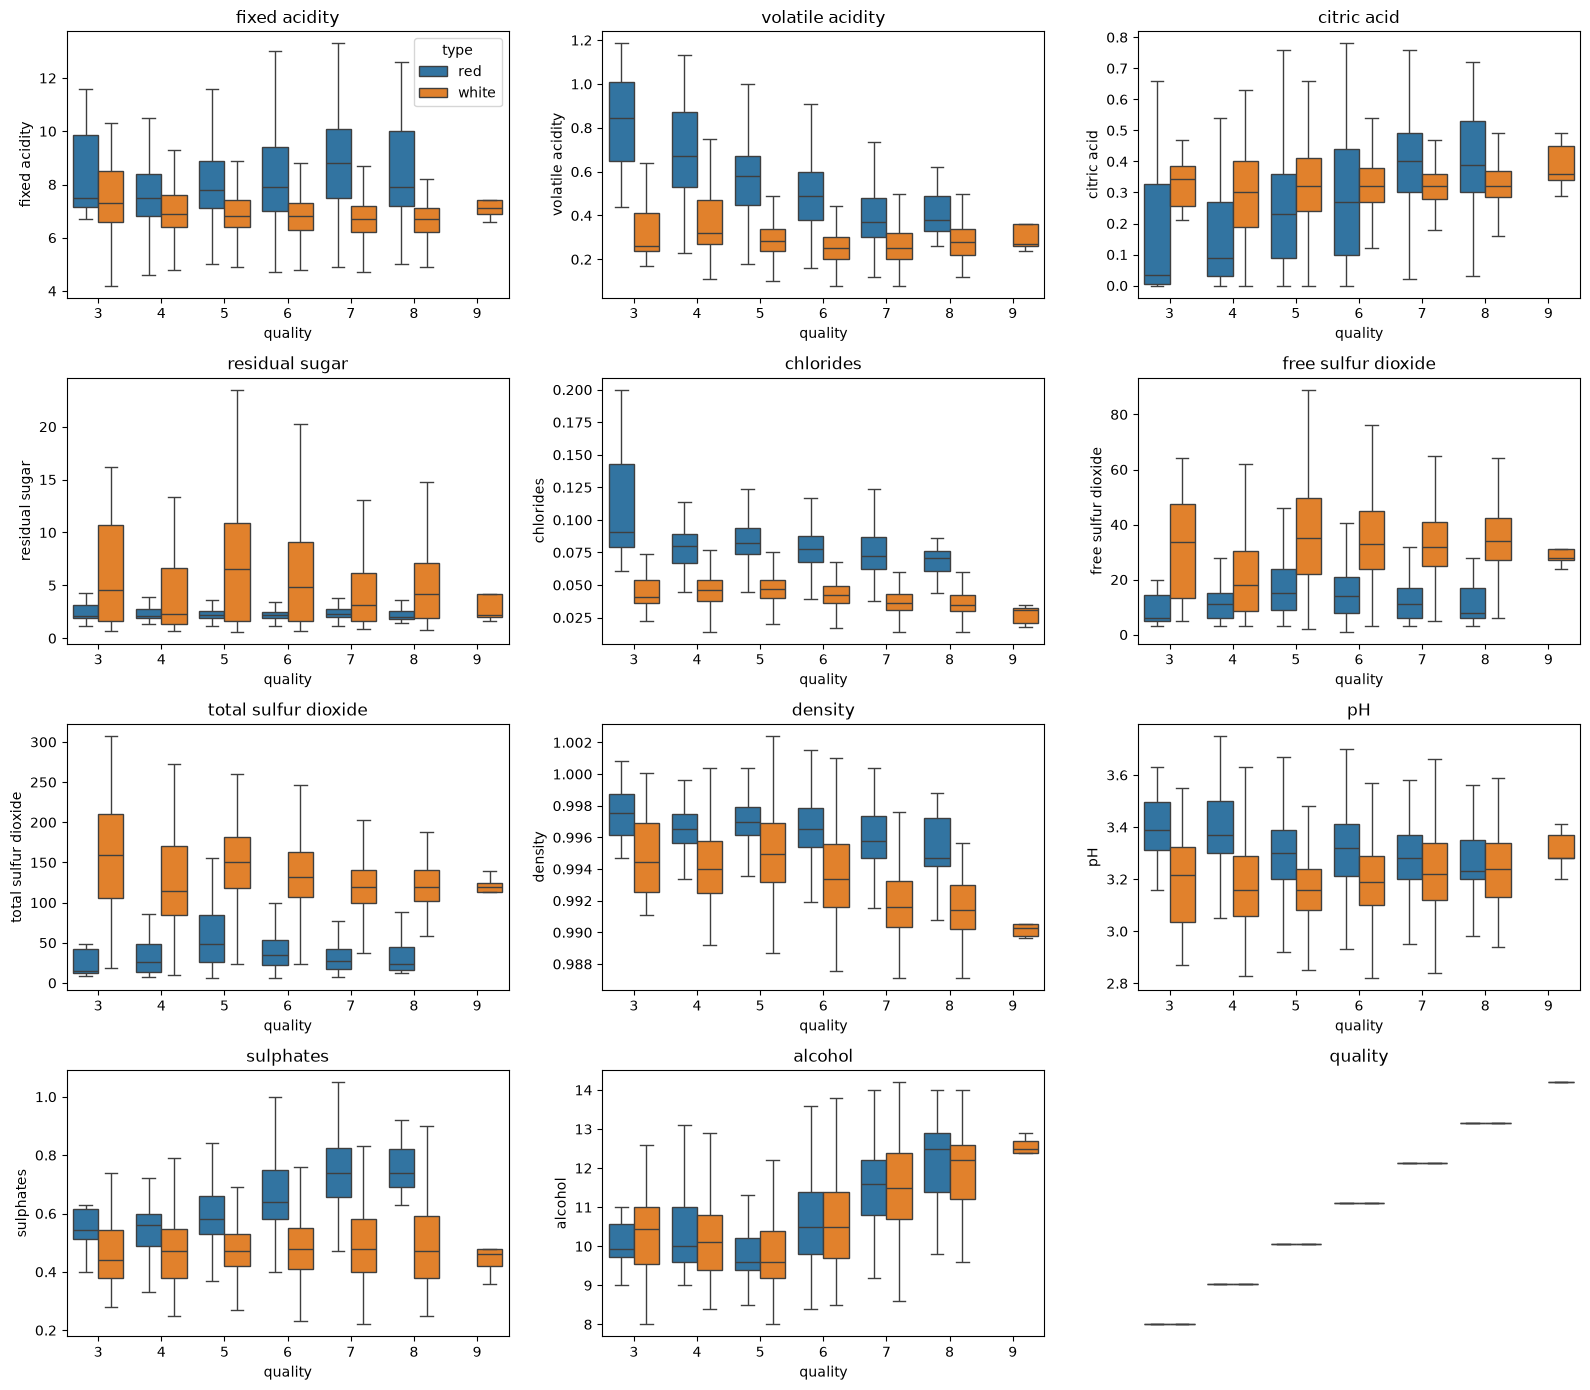

In [13]:
fig, eixos = plt.subplots(4, 3, figsize=(16, 14))

for i, (eixo, coluna) in enumerate(zip(eixos.flatten(), colunas_numericas)):
    # hue="type" separa tintos e brancos em cada nota.
    # showfliers=False esconde os outliers (já analisados na seção 5),
    # para o eixo y não esticar e a tendência entre as notas ficar visível.
    # A legenda aparece só no primeiro gráfico, para não repetir em todos.
    sns.boxplot(data=df, x="quality", y=coluna, hue="type", showfliers=False,
                legend=(i == 0), ax=eixo)
    eixo.set_title(coluna)

eixos.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Amostras por nota e tipo (o tinto não tem nenhum vinho com nota 9)
print(pd.crosstab(df["type"], df["quality"]))

# Mediana de cada variável por tipo e nota: confirma em números a tendência dos boxplots
df.groupby(["type", "quality"])[colunas_numericas].median().T.round(3)

### Observações

**1. `alcohol` é a variável com a tendência mais clara, nos dois tipos.**
A mediana sobe de 9,6 (nota 5) para 12,5 (nota 8) nos tintos e de 9,6 para 12,2 nos brancos.
→ Deve ser a variável mais importante nos modelos.

**2. Algumas variáveis só importam em um dos tipos.**
- Nos **tintos**, `volatile acidity` cai (0,58 → 0,38 da nota 5 para a 8), enquanto
  `citric acid` (0,23 → 0,39) e `sulphates` (0,58 → 0,74) sobem.
  Nos brancos, as três ficam praticamente constantes.
- Nos **brancos**, `chlorides` (0,047 → 0,035) e `density` (0,995 → 0,991) caem.
  Nos tintos, a queda é bem menor.

**3. Sem separar por tipo, essas relações ficariam escondidas.**
Como os brancos são maioria e a proporção deles cresce nas notas altas, `sulphates` e
`citric acid` pareceriam não ter relação com a qualidade. O efeito dos tintos seria
diluído pelos brancos.

**4. As notas extremas nem sempre seguem a tendência.**
Em `alcohol`, as notas 3 e 4 têm mediana maior que a nota 5, nos dois tipos. Com poucas
amostras (30 e 206 vinhos), isso pode ser variação da amostra, ou indicar que a relação
não é linear.

→ Cada variável afeta a qualidade de forma diferente em cada tipo (interação entre `type`
e as demais variáveis). Modelos baseados em árvore capturam isso sozinhos; em modelos
lineares, seria preciso criar termos de interação ou treinar um modelo por tipo.

## 7. Relações entre variáveis (scatter plots)

Pares de variáveis com relação física esperada (e correlação alta):
`density` × `alcohol`, `density` × `residual sugar` e
`free sulfur dioxide` × `total sulfur dioxide`.

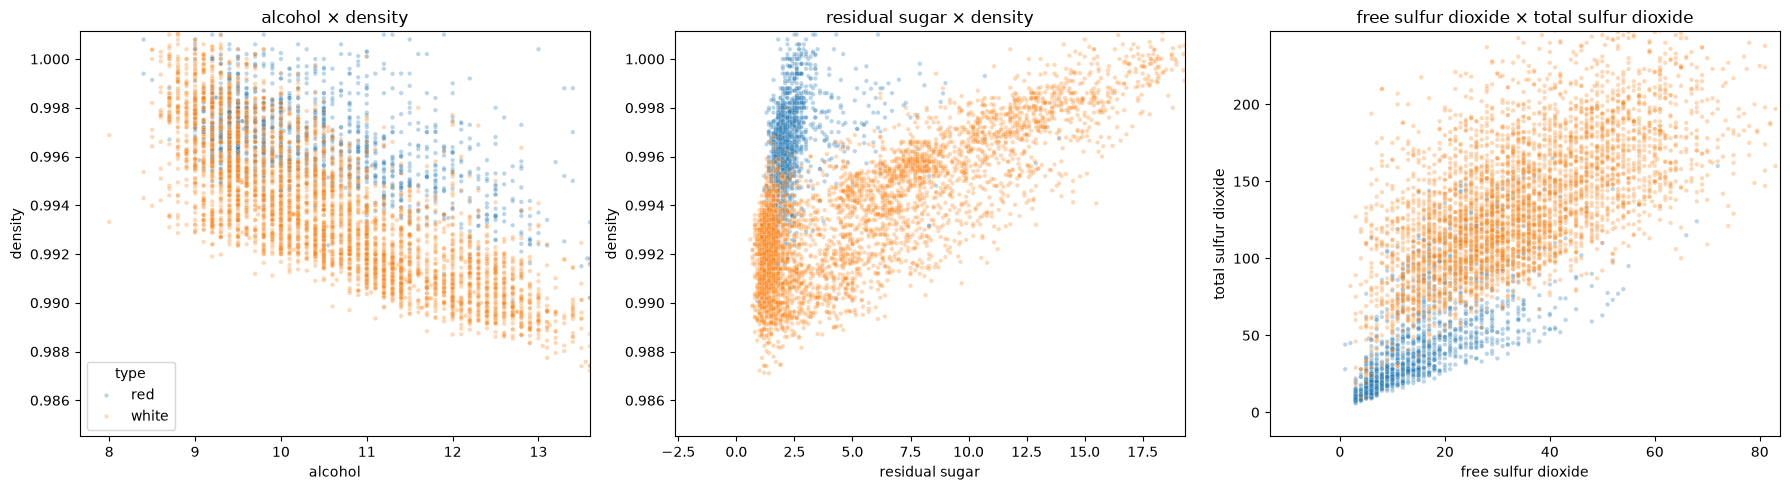

In [14]:
pares = [
    ("alcohol", "density"),
    ("residual sugar", "density"),
    ("free sulfur dioxide", "total sulfur dioxide"),
]

fig, eixos = plt.subplots(1, 3, figsize=(18, 5))

for i, (eixo, (x, y)) in enumerate(zip(eixos, pares)):
    # alpha e s (tamanho) pequenos: com 5 mil pontos, os pontos se sobrepõem
    # e a transparência mostra onde estão concentrados
    sns.scatterplot(data=df, x=x, y=y, hue="type", alpha=0.3, s=10,
                    legend=(i == 0), ax=eixo)

    # Corta o eixo em 99,5% dos dados: poucos valores extremos (ex.: residual
    # sugar 65,8) esticariam o gráfico. Os pontos continuam nos dados.
    eixo.set_xlim(right=df[x].quantile(0.995))
    eixo.set_ylim(top=df[y].quantile(0.995))
    eixo.set_title(f"{x} × {y}")

plt.tight_layout()
plt.show()

In [15]:
# Correlação de Pearson de cada par: geral e separada por tipo
correlacoes = pd.DataFrame({
    f"{x} × {y}": {
        "geral": df[x].corr(df[y]),
        **df.groupby("type")[[x, y]].apply(lambda g: g[x].corr(g[y])).to_dict(),
    }
    for x, y in pares
}).T.round(2)
correlacoes

,geral,red,white
alcohol × density,-0.67,-0.50,-0.76
residual sugar × density,0.52,0.32,0.82
free sulfur dioxide × total sulfur dioxide,0.72,0.67,0.62


### Observações

**1. `alcohol` × `density`: relação negativa (−0,67).**
O álcool é menos denso que a água, então vinhos com mais álcool são menos densos.
Isso explica por que as duas variáveis têm tendências opostas com a `quality` (seção 6):
em boa parte, são o mesmo efeito.

**2. `residual sugar` × `density`: relação positiva, forte nos brancos (0,82) e fraca nos tintos (0,32).**
O açúcar deixa o vinho mais denso. Nos tintos, quase todos são secos: o açúcar varia
pouco e a relação quase não aparece.

**3. `free` × `total sulfur dioxide`: relação positiva (0,72).**
O SO₂ livre é uma parte do total, então a relação é esperada. A correlação geral é maior
que a de cada tipo (0,67 e 0,62) porque tintos e brancos formam dois grupos separados no
gráfico: juntá-los cria uma tendência extra que não existe dentro de cada grupo.

→ **Multicolinearidade:** `density` é explicada em boa parte por `alcohol` e
`residual sugar`. Na regressão linear, isso deixa os coeficientes instáveis e difíceis de
interpretar. Podem ser usados Ridge/Lasso, avaliada a remoção de `density`, ou ao menos
interpretados os coeficientes com cautela.

## 8. Matriz de correlação

Correlação de cada variável com a `quality` e entre as próprias variáveis
(multicolinearidade, que afeta a interpretação dos coeficientes na regressão).

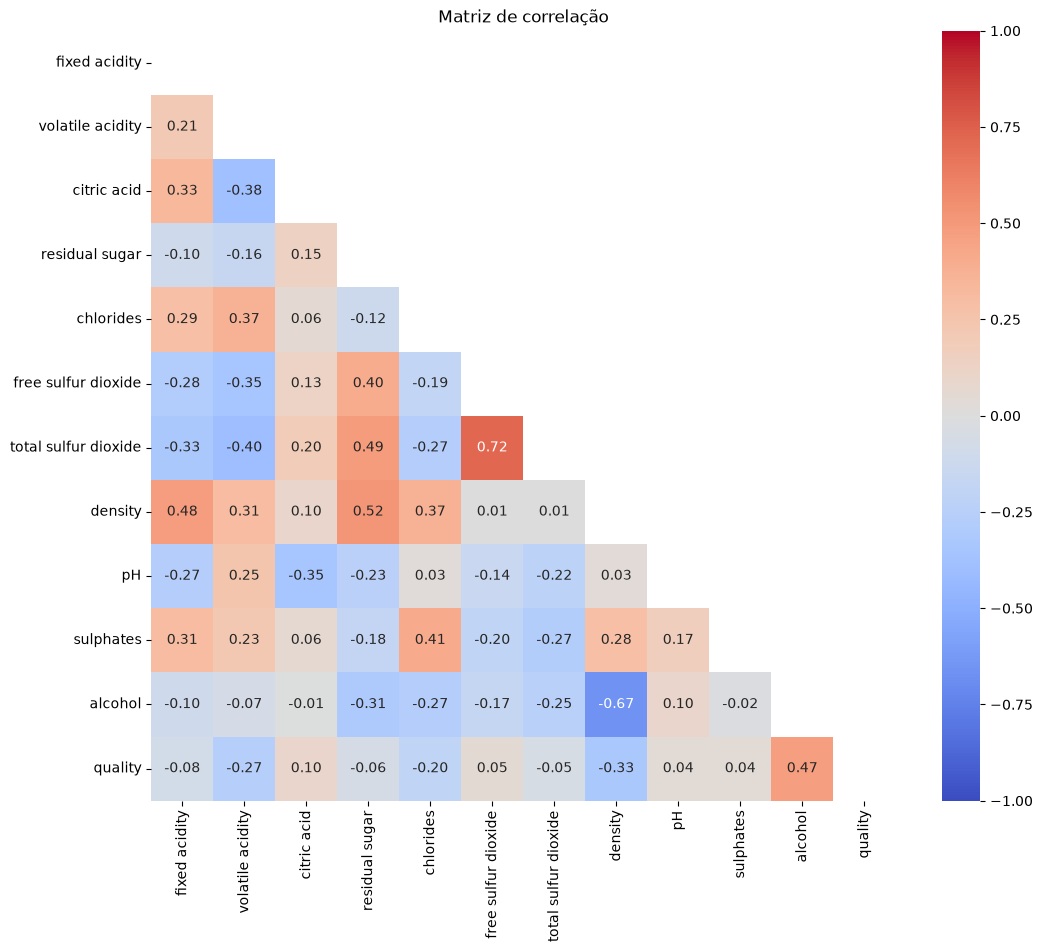

In [18]:
# Correlação de Pearson entre todas as variáveis numéricas (inclui a quality)
matriz = df.select_dtypes("number").corr()

# A matriz é espelhada (corr de A com B = corr de B com A):
# a máscara esconde a metade de cima, que repete a de baixo
mascara = np.triu(np.ones_like(matriz, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(matriz, mask=mascara, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Matriz de correlação")
plt.show()

In [19]:
# Correlação de cada variável com a quality: geral e separada por tipo
corr_quality = pd.DataFrame()
corr_quality["geral"] = df[colunas_numericas].corrwith(df["quality"])

for tipo, grupo in df.groupby("type"):
    corr_quality[tipo] = grupo[colunas_numericas].corrwith(grupo["quality"])

# Ordena pela força da correlação (valor absoluto), ignorando o sinal
corr_quality.round(2).sort_values("geral", key=abs, ascending=False)

,geral,red,white
quality,1.00,1.00,1.00
alcohol,0.47,0.48,0.46
density,-0.33,-0.18,-0.34
volatile acidity,-0.27,-0.40,-0.19
chlorides,-0.20,-0.13,-0.22
citric acid,0.10,0.23,0.01
fixed acidity,-0.08,0.12,-0.12
residual sugar,-0.06,0.01,-0.12
total sulfur dioxide,-0.05,-0.18,-0.18
free sulfur dioxide,0.05,-0.05,0.01


### Observações

**1. `alcohol` é a variável mais correlacionada com a `quality` (0,47), igual nos dois tipos.**
Em seguida vêm `density` (−0,33), `volatile acidity` (−0,27) e `chlorides` (−0,20).
As demais ficam perto de zero na coluna geral.

**2. Nenhuma correlação com a `quality` é forte.**
A maior é 0,47. A nota depende de várias variáveis ao mesmo tempo e de relações que não
são lineares.
→ É esperado um R² modesto na regressão.

**3. Separar por tipo confirma a seção 6.**
`volatile acidity` (−0,40) e `sulphates` (0,26) importam bem mais nos tintos. Na coluna
geral, `sulphates` (0,04) pareceria irrelevante.

**4. A mistura de tipos pode esconder ou criar correlações.**
- `total sulfur dioxide` tem correlação −0,05 com a `quality` no geral, mas −0,18 dentro
  de cada tipo: os brancos têm SO₂ alto e nota um pouco maior, o que cancela a relação
  negativa que existe dentro de cada tipo.
- No sentido contrário, `total sulfur dioxide` × `volatile acidity` tem −0,40 no geral,
  mas cerca de 0,1 dentro de cada tipo: a correlação vem apenas da diferença entre
  tintos e brancos.
→ Mais um argumento para incluir o `type` no modelo.

**5. Os únicos pares de features com correlação acima de 0,5 são os três da seção 7.**
`alcohol` × `density`, `residual sugar` × `density` e `free` × `total sulfur dioxide`.
A multicolinearidade está concentrada nesses pares.

## 9. Conclusões e próximos passos

### Principais achados

1. **`alcohol` é a variável mais relacionada à qualidade** (correlação ≈ 0,47),
   de forma consistente em tintos e brancos. Nenhuma outra passa de 0,40.
   Como nenhuma correlação é forte, a nota depende de várias variáveis ao mesmo
   tempo: um R² modesto na regressão é esperado.

2. **Tintos e brancos se comportam de forma diferente.** Além de terem perfis
   químicos distintos (seção 4), as variáveis afetam a nota de forma diferente em
   cada tipo: `volatile acidity`, `sulphates` e `citric acid` importam mais nos
   tintos; `chlorides` e `density`, nos brancos (seções 6 e 8). Analisar os tipos
   juntos chega a esconder relações (`sulphates`) ou apagá-las
   (`total sulfur dioxide`), porque a proporção de brancos cresce nas notas altas.

3. **O target é concentrado e desbalanceado.** As notas 5 e 6 somam cerca de 77%
   dos vinhos; as notas 3 e 9 têm 30 e 5 amostras (seção 3).

4. **Há multicolinearidade em três pares:** `alcohol` × `density`,
   `residual sugar` × `density` e `free` × `total sulfur dioxide`, todos com
   correlação acima de 0,5 e explicados pela química do vinho (seções 7 e 8).

5. **Os outliers são valores reais**, não erros: os valores impossíveis já foram
   tratados na limpeza. Representam no máximo cerca de 9% de uma variável (seção 5).

### Decisões para o pré-processamento

- Incluir **`type`** como variável do modelo (codificada como 0/1).
- Fazer o **split treino/teste estratificado** pela `quality`, para as notas raras
  aparecerem nos dois conjuntos.
- **Imputar os vazios** (`sulphates` com 95; as demais com 1 ou 2) pela mediana,
  calculada apenas no treino.
- **Manter os outliers.** Para reduzir o efeito deles, testar transformação log nas
  variáveis com cauda longa (`residual sugar`, `chlorides`, `free sulfur dioxide`,
  `sulphates`) ou o `RobustScaler`.
- **Padronizar** as variáveis para os modelos sensíveis à escala, com o scaler
  ajustado apenas no treino.

> Tudo que é "aprendido" dos dados (mediana, média, desvio padrão) é calculado só no
> treino, para não vazar informação do conjunto de teste.

### Implicações para a modelagem

**Parte 1 — Regressão**
- Os modelos tendem a prever valores perto de 5 e 6 e a errar mais nas notas extremas.
- Na regressão linear, a multicolinearidade deixa os coeficientes instáveis: usar
  regularização (Ridge/Lasso) e interpretar `density` com cautela.
- Modelos baseados em árvore (Random Forest, Gradient Boosting) devem se sair melhor,
  por capturarem sozinhos a interação entre `type` e as demais variáveis.

**Parte 2 — Classificação**
- Prever a nota exata é inviável para as notas raras: agrupar em faixas. Ponto de
  partida: **3–4** (4,4%), **5–6** (76,6%) e **7–9** (19,0%), testando outras divisões.
- As classes ficam desbalanceadas: usar métricas que não sejam dominadas pela classe
  majoritária (F1 macro, balanced accuracy) e testar `class_weight="balanced"` ou
  oversampling (aplicado só no treino).